In [1]:
import json
from train_nn import *

import json
import ufl
import dolfin as dl

#sys.path.append(os.environ.get('HIPPYLIB_PATH', "../../"))
import hippylib as hp
#sys.path.append(os.environ.get('HIPPYFLOW_PATH',"../../"))
import hippyflow as hf

In [2]:
import h5py


import os
current_folder = os.getcwd()
Sampling_type = current_folder.split("/")[-1]
print("Sampling_type:", Sampling_type)
parent_folder = os.path.dirname(current_folder)
model_name = parent_folder.split("/")[-1]
print("Model name:", model_name)



Sampling_type: unifrom
Model name: SD2LSP


In [ ]:
nx=31
ny=31
nodes = (nx+1)*(ny+1)
directory_path = "../../Results/"+str(model_name)+"/"+str(Sampling_type)+"/Nodes_"+str(nodes)
nodes = (nx+1)*(ny+1)
mesh = dl.RectangleMesh(dl.Point(0.0, 0.0), dl.Point(1.0, 1.0), nx, ny)
Vh_STATE = dl.FunctionSpace(mesh, "CG", 2)
Vh_PARAMETER = dl.FunctionSpace(mesh, "CG", 1)
Vh = [Vh_STATE, Vh_PARAMETER, Vh_STATE]

u_trial = dl.TrialFunction(Vh[hp.STATE])
u_test = dl.TestFunction(Vh[hp.STATE])

M_U = dl.assemble(dl.inner(u_trial,u_test)*dl.dx)
M_output = M_U.array()
# Path to your JSON file
filename = directory_path+ "/POD_data.h5"
with h5py.File(filename, "r") as final_data:
    c = final_data["Gempy_Inputs"][:]
    u_data = final_data["PDE_outputs"][:]
    J_data = final_data["Jacobian"][:]

In [4]:
nn_setup = NN_setup(Gempy_Inputs=c, PDE_outputs=u_data, Jacobian=J_data, Model="s")

Using MPS device
Train size: 8192,Valid size: 2730,  Test size: 2732


In [5]:
d, phi, Mphi, u_shift =nn_setup.apply_POD(Mass_Matrix=M_U, Vh=Vh)

Shape of u_data:  (8192, 3969)
8192
Using HEP
NOTE: number of data points 8192 is comparable to vector dimension 3969.
Recommend using method==ghep
Preprocessing took 3.51 seconds
Eigenvalue solve took 135 seconds
Postprocessing took 374 seconds
Basis Orthogonality error: 184.09738568038446
Basis-Projector Orthogonality error: 184.09738568038446
Mean reconstruction error: 3.104e-06
Max reconstruction error: 5.375e-06


In [6]:
d

array([ 2.58294593e-05,  6.09463962e-07,  5.71749883e-08, ...,
       -2.82225280e-22, -2.46035551e-21, -6.23961101e-21], shape=(8192,))

In [7]:
filename_final = directory_path+ "/POD_eig.h5"
with h5py.File(filename_final, "w") as final_data:
    final_data["eigen-values"] = d.tolist()

/var/folders/lr/h2867zhs72gcy61j6_cy0n0r0000gq/T/ipykernel_40664/718832458.py:2: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.arange(d.shape[0]), np.log10(d))


Text(0.5, 1.0, 'Eigenvalue distribution')

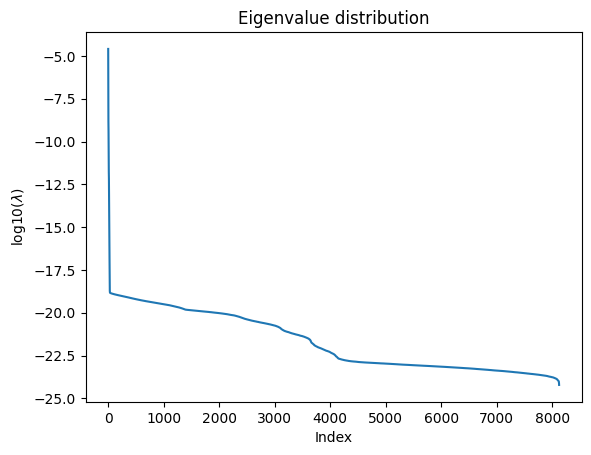

In [8]:
import matplotlib.pyplot as plt
plt.plot(np.arange(d.shape[0]), np.log10(d))
plt.xlabel("Index")
plt.ylabel("log10($\lambda$)")
plt.title("Eigenvalue distribution")

In [9]:
dK= c.shape[1]
r = np.sum(d>=1e-20)
print(r)
r =30
r

1937


30

In [10]:
sum_discarde_eig = np.sum(d[60:])
print(sum_discarde_eig)

8.511598374125709e-17


## (Linear) encoders and decoders.

Please consult our papers for a more in-depth discussion. E.g., [section 2.4 in this work](https://arxiv.org/abs/2411.12726)

We can expand a function on an orthonormal basis as

$$ u(x) = \sum_{i=1}^\infty \langle u(x),\phi_i(x)\rangle_\mathcal{U} \phi_i(x)$$

and the truncated representation

$$ u(x) = \sum_{i=1}^r \langle u(x),\phi_i(x)\rangle_\mathcal{U} \phi_i(x)$$

The encoder is the mapping from the data $u(x)$ to its truncated coefficient expansion $\mathcal{E}_r u \in \mathbb{R}^{r}$

$$ \mathcal{E}_r u = \left[\langle u,\phi_i\rangle_\mathcal{U}\right]_{i=1}^r \in \mathbb{R}^{r}$$

The decoder maps this data back to the function space (e.g., the basis expansion operation), given $\alpha \in \mathbb{R}^r$ we have

$$ \mathcal{D}_r \alpha  = \sum_{i=1}^r \alpha_i \phi_i$$

The encoder has the effect of the inner product $\langle \cdot,\cdot\rangle_\mathcal{U}$, e.g., the mass matrix in finite elements, each column of it is $\langle \cdot, \phi\rangle_\mathcal{U}$, so we call it `Mphi` $\in \mathbb{R}^{d_u \times r}$. Likewise we call the decoder `\phi` since its columns are just the basis vectors

### Encoding u data

The mapping to the coefficients of u is $u_r = \mathcal{E}_r u$. In numpy this is `ur_data = Mphi.T@u_data`

### Decoding the u data

We decode with the basis: $\mathcal{D}_r u_r$. In numpy this is `phi@ur_data`

### Encoding and decoding the derivatives.

The derivative of the map is 

$$ Du(c) \in \mathcal{L}(\mathbb{R}^{d_c},\mathcal{U}) $$

that is, the space of linear operators from $\mathbb{R}^{d_c}$ into $\mathcal{U}$. We want to remove the high-dimensionality associated with $\mathcal{U}$

This is done with the encoder operator:

$$\mathcal{E}_r Du(c) \in \mathbb{R}^{r\times d_c}$$

In [10]:
Mphi_r = Mphi[:, :r]
phi_r = phi[:,:r]
Mphi_r.shape, phi_r.shape

((3969, 30), (3969, 30))

In [11]:
#Save to file
np.save('./saved_model/Mphi_r.npy', Mphi_r)
np.save('./saved_model/phi_r.npy', phi_r)
np.save('./saved_model/u_shift.npy', u_shift)

In [12]:
Dur = np.einsum('ru,duc->drc',Mphi_r.T,J_data)
Dur_re = np.einsum('ru, duc->drc', phi_r, Dur)

In [13]:
Frobenius_norm = calulate_matrix_norm_square(torch.tensor(J_data), torch.tensor(Dur_re), torch.tensor(M_output))
A_T_M_A = torch.einsum("bmi, mk, bkj->bij", torch.tensor(J_data), torch.tensor(M_output), torch.tensor(J_data),)
true_matrix_norm = torch.einsum("bii->b", A_T_M_A)
H1 = 1 - torch.sqrt(torch.sum((Frobenius_norm)/true_matrix_norm))
print("H1 accuracy : ", H1)

H1 accuracy :  tensor(1.0000, dtype=torch.float64)


In [14]:
nn_setup.set_POD_matrices(Decoder_matrix=phi_r, bias=u_shift)

In [ ]:

lr = 0.002
layer_sizes=[dK,2*dK, 4*dK, 8*dK, 16*dK, r,r,r]


In [17]:
epoch=200
nn_setup.train_network_M2(layer_sizes=layer_sizes, num_epochs=epoch, lr =lr)

Epoch [0/200], Train Loss: 0.0098, Val Loss: 0.0024
Epoch [10/200], Train Loss: 0.0000, Val Loss: 0.0002
Epoch [20/200], Train Loss: 0.0000, Val Loss: 0.0007
Epoch [30/200], Train Loss: 0.0000, Val Loss: 0.0005
Epoch [40/200], Train Loss: 0.0000, Val Loss: 0.0004
Epoch [50/200], Train Loss: 0.0000, Val Loss: 0.0008
Epoch [60/200], Train Loss: 0.0000, Val Loss: 0.0002
Epoch [70/200], Train Loss: 0.0000, Val Loss: 0.0002
Epoch [80/200], Train Loss: 0.0000, Val Loss: 0.0001
Epoch [90/200], Train Loss: 0.0000, Val Loss: 0.0002
Epoch [100/200], Train Loss: 0.0000, Val Loss: 0.0000
Epoch [110/200], Train Loss: 0.0000, Val Loss: 0.0000
Epoch [120/200], Train Loss: 0.0000, Val Loss: 0.0000
Epoch [130/200], Train Loss: 0.0000, Val Loss: 0.0001
Epoch [140/200], Train Loss: 0.0000, Val Loss: 0.0000
Epoch [150/200], Train Loss: 0.0000, Val Loss: 0.0001
Epoch [160/200], Train Loss: 0.0000, Val Loss: 0.0000
Epoch [170/200], Train Loss: 0.0000, Val Loss: 0.0000
Epoch [180/200], Train Loss: 0.0000, Va

In [18]:
nn_setup.train_network_Jacobian_full(layer_sizes=layer_sizes, num_epochs=epoch, scale_factor=1, lr=lr)

Epoch [0/200], Train Loss: 0.0012, Val Loss: 0.0009, L2 Loss: 0.0000, F2 Loss: 0.0012
Epoch [10/200], Train Loss: 0.0007, Val Loss: 0.0007, L2 Loss: 0.0000, F2 Loss: 0.0007
Epoch [20/200], Train Loss: 0.0007, Val Loss: 0.0006, L2 Loss: 0.0000, F2 Loss: 0.0007
Epoch [30/200], Train Loss: 0.0006, Val Loss: 0.0006, L2 Loss: 0.0000, F2 Loss: 0.0006
Epoch [40/200], Train Loss: 0.0006, Val Loss: 0.0006, L2 Loss: 0.0000, F2 Loss: 0.0006
Epoch [50/200], Train Loss: 0.0006, Val Loss: 0.0006, L2 Loss: 0.0000, F2 Loss: 0.0006
Epoch [60/200], Train Loss: 0.0003, Val Loss: 0.0003, L2 Loss: 0.0000, F2 Loss: 0.0003
Epoch [70/200], Train Loss: 0.0002, Val Loss: 0.0002, L2 Loss: 0.0000, F2 Loss: 0.0002
Epoch [80/200], Train Loss: 0.0001, Val Loss: 0.0001, L2 Loss: 0.0000, F2 Loss: 0.0001
Epoch [90/200], Train Loss: 0.0001, Val Loss: 0.0001, L2 Loss: 0.0000, F2 Loss: 0.0001
Epoch [100/200], Train Loss: 0.0000, Val Loss: 0.0000, L2 Loss: 0.0000, F2 Loss: 0.0000
Epoch [110/200], Train Loss: 0.0000, Val Lo